In [73]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict

In [74]:
load_dotenv()

True

In [75]:
llm = ChatGoogleGenerativeAI(
    model = 'gemini-2.5-flash'
)

In [76]:
#define state

class BlogState(TypedDict):
    topic: str
    blog: str
    outline: str
    eval: int
    



In [77]:
def gen_blog_outline(state: BlogState) -> BlogState:

    # extract the topic
    topic = state['topic']

    #form a prompt
    prompt = f'You are the expert blog writer write only a clear outline for the blog on the topic - {topic}'


    #ask question to LLm
    outline = llm.invoke(prompt).content


    #update answer to the state 
    state['outline'] = outline

    return state


In [78]:
def write_blog(state: BlogState) -> BlogState:

    # extract the outline 
    outline = state['outline']
    topic = state['topic']

    #form a prompt
    prompt = f'You are the expert blog writer write a short blog on the title - {topic} using the following outlines \n {outline}'


    #ask question to LLm
    blog = llm.invoke(prompt).content


    #update answer to the state 
    state['blog'] = blog

    return state


In [79]:
def gen_eval(state: BlogState) -> BlogState:

    outline = state['outline']
    blog = state['blog']

    prompt = f'You are a expert blog writer rate my blog {blog} according to the this outline {outline}'

    eval = llm.invoke(prompt).content

    state['eval'] = eval

    return state


In [80]:
#create graph
graph = StateGraph(BlogState)

#Add node
graph.add_node('gen_blog_outline', gen_blog_outline)
graph.add_node('write_blog', write_blog)
graph.add_node('gen_eval', gen_eval)
#Add Edges
graph.add_edge(START, 'gen_blog_outline')
graph.add_edge('gen_blog_outline', 'write_blog')
graph.add_edge('write_blog', 'gen_eval')
graph.add_edge('gen_eval', END)

#Compile
workflow = graph.compile()

In [81]:
#execute
intail_state = {'topic': 'Rise of AI in Agriculture'}
final_state = workflow.invoke(intail_state)

print(final_state['outline'])

Here is a clear outline for a blog post on "Rise of AI in Agriculture":

---

**Blog Title: Cultivating the Future: The Rise of AI in Agriculture**

**I. Introduction**
    A. Hook: The age-old practice of farming meets cutting-edge technology.
    B. Context: Global challenges – feeding a growing population, climate change, resource scarcity, labor shortages.
    C. Thesis: Artificial Intelligence is revolutionizing agriculture, promising unprecedented efficiency, sustainability, and productivity.
    D. What the Blog Will Cover: Explore key applications, benefits, and challenges of AI in farming.

**II. What is AI in Agriculture? (A Brief Overview)**
    A. Beyond Robots: Defining AI (Machine Learning, Computer Vision, Predictive Analytics).
    B. How it Works: Data collection (sensors, drones, satellites) -> Analysis -> Informed Decision-Making -> Automation.

**III. Key Applications: How AI is Transforming the Farm**
    A. **Precision Farming & Crop Management**
        1.  **Soi

In [82]:
print(final_state['blog'])

## Cultivating the Future: The Rise of AI in Agriculture

For millennia, farming has been an age-old practice, deeply rooted in tradition and human intuition. Today, this essential industry is meeting cutting-edge technology head-on. As our planet faces immense global challenges – feeding a growing population, battling climate change, managing resource scarcity, and addressing labor shortages – Artificial Intelligence (AI) is emerging as a revolutionary force. AI promises to transform agriculture, ushering in unprecedented levels of efficiency, sustainability, and productivity. Let's delve into how AI is reshaping the farm, exploring its key applications, undeniable benefits, and the hurdles we must overcome.

### What is AI in Agriculture? Beyond the Robot Tractor

When we talk about AI in agriculture, we're looking beyond just self-driving tractors (though they're certainly part of it!). AI encompasses sophisticated technologies like Machine Learning (ML), Computer Vision, and Predic

In [83]:
print(final_state['eval'])

This is an **outstanding** blog post! As an expert blog writer, I can confidently say you've hit all the marks.

**Overall Rating: 9.8/10**

Here's a detailed breakdown:

---

### Expert Review: "Cultivating the Future: The Rise of AI in Agriculture"

**1. Adherence to Outline (10/10):**
You followed your provided outline meticulously. Every section, every sub-point, is covered comprehensively and in the correct order. This creates a logical, easy-to-follow structure for the reader.

**2. Engagement & Hook (10/10):**
The introduction is excellent. It starts with a compelling hook ("For millennia, farming has been an age-old practice...") that immediately grounds the reader in the topic before pivoting to the modern challenges and the role of AI. The thesis statement is clear and sets the stage perfectly for what's to come.

**3. Clarity & Accessibility (10/10):**
Despite discussing complex technology, your language is incredibly clear and accessible. You successfully define AI in agric

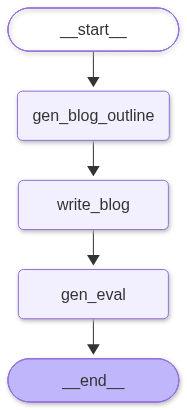

In [71]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())